# SLU03 - Visualization with Pandas and Matplotlib: Exercise notebook

In this exercise notebook, we will explore various data visualization techniques using the "ds_salaries" dataset from https://www.kaggle.com/datasets/iamsouravbanerjee/data-science-salaries-2023. Our main objective is to gain insights if it is worth doing this data science course at all. ;) Therefore we look at the factors that influence data science job salaries and understand the salary trends in the field.

Start by importing these packages:

In [30]:
import hashlib
import json
import pandas as pd
import numpy as np
import plotchecker
from plotchecker import PlotChecker
import seaborn as sns
import utils

def _hash(s):
    """Function used to hash the answers."""
    return hashlib.sha256(json.dumps(s).encode()).hexdigest()

In [31]:
# Load the dataset
ds_salaries = pd.read_csv("data/Latest_Data_Science_Salaries.csv")

# Display the first few rows of the modified DataFrame
rows, columns = ds_salaries.shape
print(f'ds_salaries: {rows} records and {columns} fields.');
ds_salaries.head()

ds_salaries: 3300 records and 11 fields.


,Job Title,Employment Type,Experience Level,Expertise Level,Salary,Salary Currency,Company Location,Salary in USD,Employee Residence,Company Size,Year
0,Data Engineer,Full-Time,Senior,Expert,210000,United States Dollar,United States,210000,United States,Medium,2023
1,Data Engineer,Full-Time,Senior,Expert,165000,United States Dollar,United States,165000,United States,Medium,2023
2,Data Engineer,Full-Time,Senior,Expert,185900,United States Dollar,United States,185900,United States,Medium,2023
3,Data Engineer,Full-Time,Senior,Expert,129300,United States Dollar,United States,129300,United States,Medium,2023
4,Data Scientist,Full-Time,Senior,Expert,140000,United States Dollar,United States,140000,United States,Medium,2023


For these exercises we will use the `matplotlib.pyplot` module. We will start by importing it.

In [32]:
import matplotlib.pyplot as plt

## Exercise 1 - Default plot parameters

To start, you are going to change the default plot settings as follows:
* change the default pyplot chart size to 4 inches width and 4 inches height
* change the linewidth to 3   
* change the linestyle to be a dotted line '.'

In [33]:
# YOUR CODE HERE
plt.rcParams['figure.figsize'] = (4, 4)
plt.rcParams['lines.linewidth'] = 3
plt.rcParams['lines.linestyle'] = ':'

In [34]:
# Check the default figure size
assert plt.rcParams['figure.figsize'] == [4.0, 4.0], 'Default figure size is incorrect'

# Check the default line width
assert plt.rcParams['lines.linewidth'] == 3, 'Default line width is incorrect'

# Check the default line style
assert plt.rcParams['lines.linestyle'] == ':', 'Default line style is incorrect'

print('It seems to work! I am curious how it will look like. You too?')

It seems to work! I am curious how it will look like. You too?


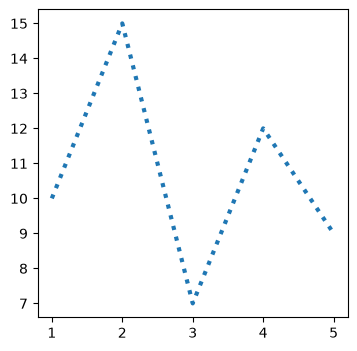

In [35]:
# lets see how those settings look like with the following dataset
x = [1, 2, 3, 4, 5]
y = [10, 15, 7, 12, 9]

plt.plot(x,y); # ps.. do you remember the reason why we use ";" here?

## 🛑 An important note about the grading

**Grading plots is difficult**. We are using `plotchecker` to grade the plots with `nbgrader`. For `plotchecker` to work with `nbgrader`, **we need to add in each cell this line**:

> **`axis = plt.gca();`**

**after the code required** to do the plot. Make sure to keep this line in the plotting cells.

For example, if we want to plot a `scatter plot` showing the relationship between `Employee Residence` and `Salary in USD`  columns, we would do as follows:

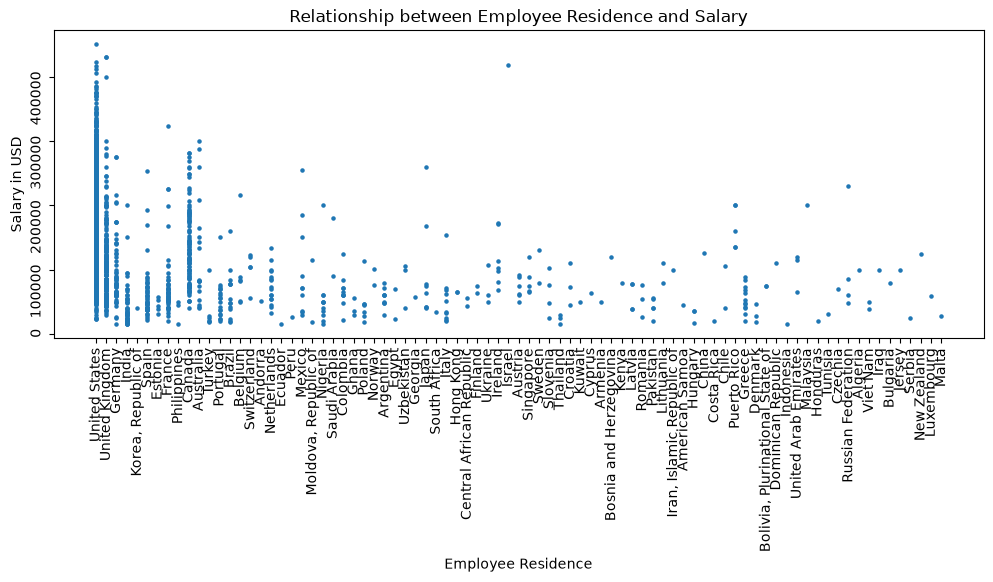

In [36]:
# Create a scatter plot
scatter_plot = ds_salaries.plot.scatter(x='Employee Residence', y='Salary in USD', s=5, figsize=(12,4))

# Rotate x-axis labels vertically
scatter_plot.axes.tick_params(rotation=90)

# Set labels and title
plt.xlabel('Employee Residence')
plt.ylabel('Salary in USD')
plt.title('Relationship between Employee Residence and Salary')

# Last line in the cell required to "capture" the cell and grade it with nbgrader
axis = plt.gca();

## Exercise 2 - Average salary per employee residence location

In the above scatter plot we see the salary by employee residence location. This is not the best way to visualize this data. Maybe we look at a better way later on.

Now an easier question. What is the best way to show the average salary for different employee residence locations?

    A. Scatter plot   
    B. Line chart   
    C. Histogram   
    D. Bar plot
    
Leave your answer below, assigned to the `exercise_2_plot_type` variable as a string. For example:
```
exercise_2_plot_type = 'E'
```

In [37]:
# exercise_2_plot_type =
# YOUR CODE HERE
exercise_2_plot_type = 'D'

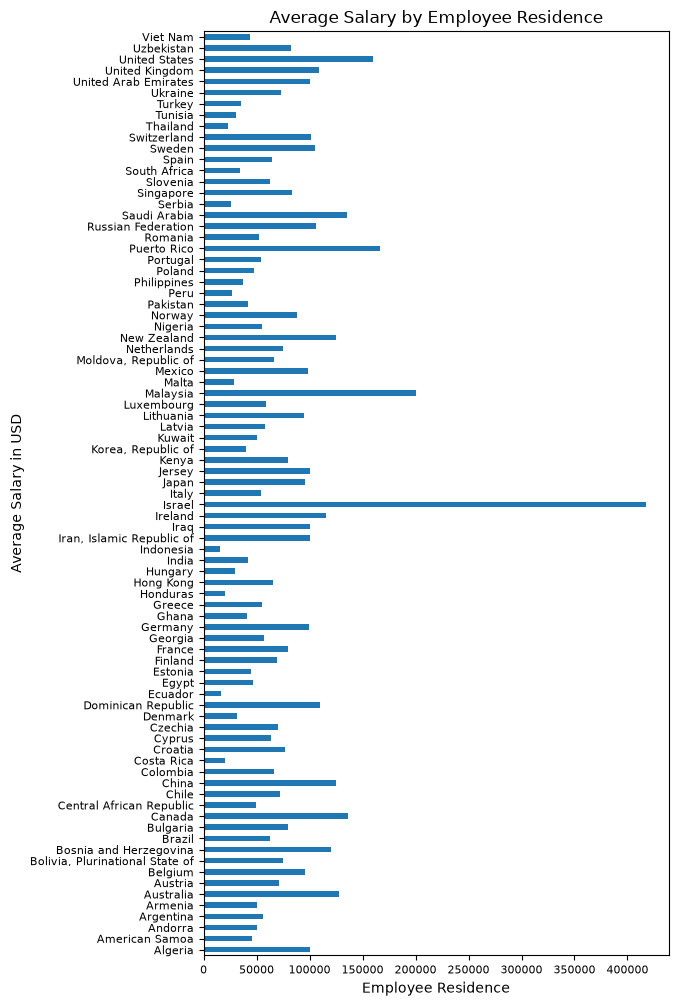

That is correct. Great! Here you can see an example of the plot.
We're choosing a horizontal bar plot because Employee Residence is a nominal categorical variable.


In [38]:
assert _hash(exercise_2_plot_type) == '8f097023401b3d58704c1f3abea8ec2eba57c387f09d10125cd66076afd13b1e', 'Try again'

plot = ds_salaries.groupby('Employee Residence')['Salary in USD'].mean().plot.barh(figsize=(6, 12), fontsize=8)
plot.set_xlabel('Employee Residence')
plot.set_ylabel('Average Salary in USD')
for i in plot.get_xticklabels()+plot.get_yticklabels(): # here we make the axis labels smaller
    i.set_fontsize(8)
plot.set_title('Average Salary by Employee Residence')
plt.show()
    
print('''That is correct. Great! Here you can see an example of the plot.
We're choosing a horizontal bar plot because Employee Residence is a nominal categorical variable.''')

You can see that the salaries vary widely between countries. We also have very few data points for most countries. To make meaningful comparisons, we will use just data from United States in the following exercises.

In [39]:
ds_salaries_us = ds_salaries[ds_salaries['Employee Residence']=='United States']
f'The reduced dataset ds_salaries_us has {ds_salaries_us.shape[0]} rows.'

'The reduced dataset ds_salaries_us has 2453 rows.'

## Exercise 3 - Salary vs. experience

Let's explore salary vs. job experience in the `ds_salaries_us` dataset. A scatter plot or a line chart is suitable for this purpose. A scatter plot can show the relationship between salary and experience levels for individual data points. A line chart can help visualize trends in how salaries vary with different levels of experience. 

The experience level has the following possible values from most to least senior: 'Executive', 'Senior', 'Mid', 'Entry'.

Make a line chart with the following settings:

- set the plot title to `Salary vs. Experience`.
- label the x-axis as `Experience Level`.
- label the y-axis as `Salary`.

Before plotting, we will reset matplotlib's parameters to the default ones.

In [40]:
plt.style.use('default')

We will calculate the mean salaries for each experience level for you. The result is stored in the `grouped_by_experience` dataframe. Use this dataframe for plotting.

In [41]:
grouped_by_experience = utils.ex_3_dataset(ds_salaries_us)
grouped_by_experience

,Experience Level,Salary
0,Entry,103047.642857
1,Mid,134818.779775
2,Senior,168193.682028
3,Executive,204479.127119


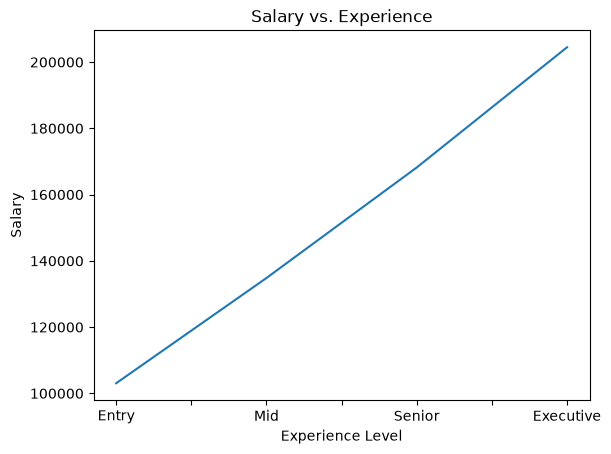

In [42]:
# Create a line chart from the grouped_by_expertise dataframe.

# YOUR CODE HERE
grouped_by_experience.plot.line(x='Experience Level', y='Salary', legend=False)
plt.title('Salary vs. Experience')
plt.xlabel('Experience Level')
plt.ylabel('Salary')

axis = plt.gca();

In [43]:
pc = PlotChecker(axis)

assert pc.xlabel=='Experience Level',  "Did you set the correct variables for the plot axes?"
assert pc.ylabel=='Salary',  "Did you set the correct variables for the plot axes?"
assert pc.title=='Salary vs. Experience', 'Did you use the correct plot title?'
assert len([x for x in ['Entry','Mid','Senior','Executive'] if x in pc.xticklabels])==4, 'Did you plot the correct data?'
assert len(pc.axis.get_lines())==1, 'There should be just one line in the plot.'
assert len([int(round(x,2)==round(p,2)) for x,p in zip(pc.axis.get_lines()[0].get_ydata(),grouped_by_experience['Salary'])]
          )==4, 'The data points in the line are not correct.'
assert pc.ylim[0]<=100384, 'Did you use the correct data to plot?'
assert pc.ylim[1]>=203987, 'Did you use the correct data to plot?'
print('Good news! Getting more experience gets you a better salary.')

Good news! Getting more experience gets you a better salary.


## Exercise 4 - Salary by company size

### Exercise 4.1 - Choose the plot type

Now we'd like to analyze the salaries by company size. We'd like to see the salary distribution for each company size. Which plot is the best to visualize this?

    A. Line chart  
    B. Box plot   
    C. Bar plot   
    D. Histogram   

In [44]:
#exercise_4_plot_type = ...
# YOUR CODE HERE
exercise_4_plot_type = 'B'

In [45]:
assert _hash(exercise_4_plot_type) == '955cca1ceba45052d85984d3a2565f4ce25b7488602c60a165598bf80b26e472', 'Try again.'

print('YES! Indeed, that one is great for this. Lets make one! ')

YES! Indeed, that one is great for this. Lets make one! 


### Exercise 4.2 - Make the plot

Construct the salary vs. company size plot with the following parameters:

* Use `Company size` and `Salary` from the `ds_salaries_us` dataframe
* set the figure size to 6 inches wide and 4 inches tall
* use fontsize 9 for the axis labels
* label x as 'Salary' with font size 12
* label y as 'Company Size' with font size 12
* use plot title as 'Salary Distribution by Company Size' with font size 14
* change the default plot style to 'bmh'
* suppress the default title with `plt.suptitle('')`

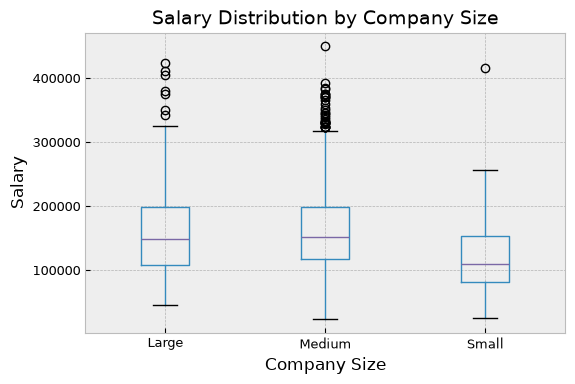

In [46]:
# YOUR CODE HERE
plt.style.use('bmh')   # must come before plotting
ds_salaries_us.boxplot(column='Salary', by='Company Size', figsize=(6, 4), fontsize=9)
plt.suptitle('')
plt.title('Salary Distribution by Company Size', fontsize=14)
plt.xlabel('Company Size', fontsize=12)
plt.ylabel('Salary', fontsize=12)

axis = plt.gca(); 

In [47]:
pc = PlotChecker(axis)
assert pc.ylabel == 'Salary', 'Are the axis labels correct?'
assert pc.xlabel == 'Company Size', 'Are the axis labels correct?'
assert pc.title == 'Salary Distribution by Company Size', 'Did you put the correct title?'
assert len([x for x in ds_salaries_us['Company Size'].unique() if x in pc.xticklabels])==3,\
'Did you use the correct data to plot?'
assert pc.ylim[0]<=ds_salaries_us['Salary'].min() and pc.ylim[1]>=ds_salaries_us['Salary'].max(), \
'Did you use the correct data to plot?'
print('''That was AWESOME!! Did you already make up your mind in which size of company you want to work?
Please pay attention to those lost dots btw. We call them outliers and we will get back to that.''')

That was AWESOME!! Did you already make up your mind in which size of company you want to work?
Please pay attention to those lost dots btw. We call them outliers and we will get back to that.


### Exercise 4.3 - Answer questions about the plot
Now answer the following questions based on the plot you just plotted in exercise 4.2.

1. Which company size has the highest lying outliers? Assign the answer to the `highest_outlier` variable.
2. Which company size has the smallest interquartile range? Assign the answer to the variable `smallest_IQR`.

In [48]:
#highest_outlier = ...
#smallest_IQR = ...

# YOUR CODE HERE
g = ds_salaries_us.groupby('Company Size')['Salary']
highest_outlier = g.max().idxmax()
smallest_IQR = (g.quantile(0.75) - g.quantile(0.25)).idxmin()

In [49]:
assert _hash(highest_outlier.lower())=='60d4c90eee5e731df8d3ef2891de541d2e755ff8ee9db358e26bdec49f6e0db9', \
'Check those outliers again.'
assert _hash(smallest_IQR.lower())=='300694740fd6f600a0011c69d5ceb0604f79dd7f96b0cbd87ffb1952d614a7ff', \
'What was the interquartile range again? Maybe you should check. ;)'
print('Perfect!')

Perfect!


## Exercise 5 - Plot for visualizing correlations

Often we want to check if our assumptions are true. We imagine that some of our variables will be influenced by each other or by the same factors. Which plot is the most useful to help us understand the relationship between two variables?

    A. Box plot   
    B. Pie plot  
    C. Scatter plot   
    D. Histogram

In [50]:
#exercise_5_plot_type = ...
# YOUR CODE HERE
exercise_5_plot_type = 'C'

In [51]:
assert _hash(exercise_5_plot_type) == 'c2e8c0cc2e73b9bd1ba9ef1979e73169b471e25b0e9909efe98fde462c0bf55f', 'Try again'
print('''Yes indeed! It is a great start to use this plot when you want to understand your variables. 
Run the cell below to see how a positive correlation looks like. But no worry if this is new to you, 
you are going to learn more about this subject later.''')

Yes indeed! It is a great start to use this plot when you want to understand your variables. 
Run the cell below to see how a positive correlation looks like. But no worry if this is new to you, 
you are going to learn more about this subject later.


Check out this plot where the variables have a positive correlation:

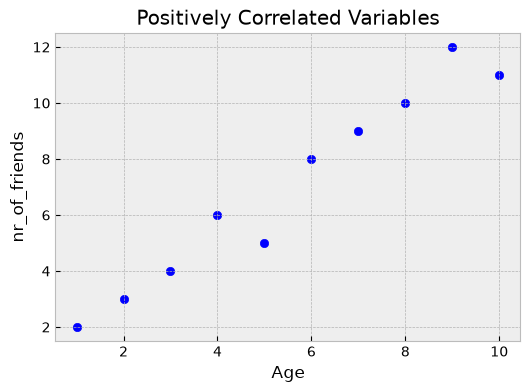

In [52]:
# Two variables with a positive correlation
age = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
nr_of_friends = np.array([2, 3, 4, 6, 5, 8, 9, 10, 12, 11])

# Create the plot
plt.figure(figsize=(6, 4))
plt.scatter(age, nr_of_friends, color='b', marker='o')
plt.xlabel('Age')
plt.ylabel('nr_of_friends')
plt.title('Positively Correlated Variables');

## Exercise 6 - Median Salary by Job Title

We already saw the correlation between `Salary` and `Experience Level`. Let's make another visualization to show off your skills. We're going to make another bar plot, this time exploring the relationship between `Salary` and some `Job Titles`.

We will use this dataframe with median salary for the selected job titles:

In [53]:
median_salary_by_job_title = utils.ex_6_dataset(ds_salaries_us)
median_salary_by_job_title

Job Title
Data Analyst      113220.0
Data Engineer     151920.0
Data Scientist    155000.0
Name: Salary, dtype: float64

Plot a bar plot using the `median_salary_by_job_title` dataset and add the following extra information:

- label the x-axis as `Salary (median)`.
- label the y-axis as `Job Title`.
- change the plot color to `tab:pink`.
- name the title `Median Salary by Job Title`

Choose the appropriate bar plot type (horizontal or vertical) based on the variable type.

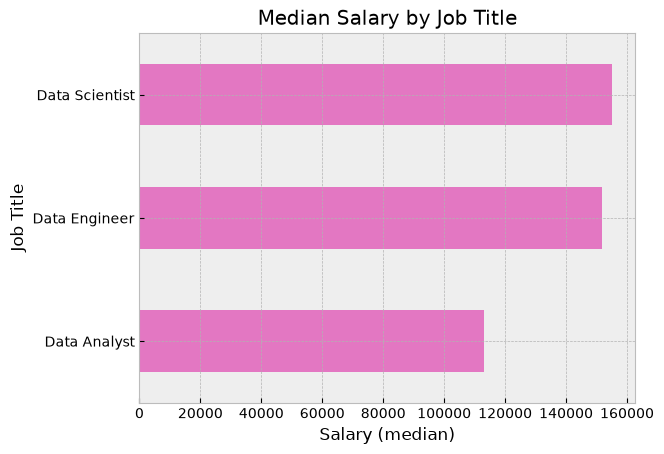

In [54]:
# YOUR CODE HERE
median_salary_by_job_title.plot.barh(color='tab:pink')
plt.xlabel('Salary (median)')
plt.ylabel('Job Title')
plt.title('Median Salary by Job Title')
axis = plt.gca();

In [55]:
pc = PlotChecker(axis)
pc.assert_xlabel_equal('Salary (median)'), "The x label seems wrong"
pc.assert_ylabel_equal('Job Title'), "The y label seems wrong"
pc.assert_title_equal('Median Salary by Job Title'), "Did you put a title for your plot?"
assert len(pc.axis.patches)==3, 'The number of bars in the plot is not correct.'
assert len([int(x.get_width()==s) for x,s in zip(pc.axis.patches,median_salary_by_job_title)])==3, \
'Did you plot the correct dataset in the correct orientation?'
assert pc.axis.patches[0].get_facecolor()==(0.8901960784313725, 0.4666666666666667, 0.7607843137254902, 1.0), 'Did you use the correct color?'
assert pc.xlim[0]<=0 and pc.xlim[1]>=median_salary_by_job_title.max(), \
'Did you plot the correct dataset in the correct orientation?'
assert len([x for x in pc.yticklabels if x in ['Data Analyst', 'Data Engineer', 'Data Scientist']])==3, \
'Did you plot the correct dataset in the correct orientation?'
print('That looks beautiful. You are on a roll!')

That looks beautiful. You are on a roll!


## Exercise 7 - Plot for distributions

### Exercise 7.1 - Choose the plot type

There is another plot that can tell us a lot about the statistics of the data. These are usually plots that show us the distribution of variables. 

Which plot can we use to visualize how the `Salary` is distributed in a given employee residence location?

    A. Histogram   
    B. Bar plot  
    C. Box plot   
    D. Pie plot

In [56]:
#exercise_7_plot_type = ...
# YOUR CODE HERE
exercise_7_plot_type = 'A'

In [57]:
assert _hash(exercise_7_plot_type) == '798640599597df7a8daa32b1132f07850a68b5e71bd295650399a38074f52804', 'Try again'
print('--- Success ---')

--- Success ---


### Exercise 7.2 - Make the plot
There are too many countries of employee residence, so instead we're going to use this plot to visualize the distribution of salaries for different experience levels. All in the same plot! Use the `ds_salaries_us` dataframe. You'll have to check the documentation or google around for this exercise.

- create a plot with a distribution for each `Experience Level` - sort them in order of seniority
- make each distribution a different color, using the colors ['tab:blue', 'tab:orange', 'tab:purple', 'tab:brown']
- use bin width of 10000
- the bin edges should be from 40000 to 150000
- normalize the histogram - set `density` to `True`
- use this formatting:   
    - set the edgecolor to black   
    - set the opacity to 0.8   
- x label should be 'Salary'
- y label should be 'Number of Employees'
- title of the plot should be 'Salary Distribution by Experience Level'
- add a legend to display the experience levels

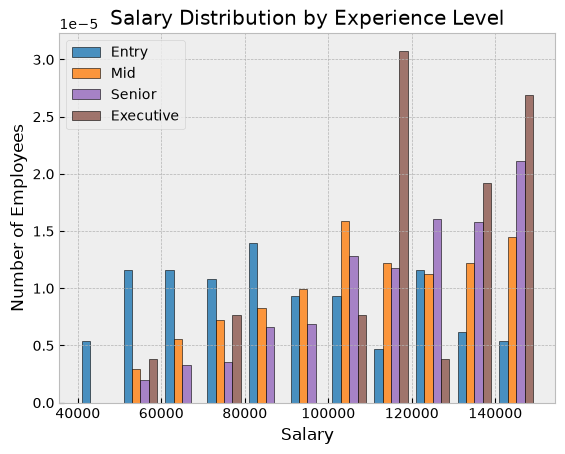

In [58]:
# YOUR CODE HERE
levels = ['Entry', 'Mid', 'Senior', 'Executive']
data = [ds_salaries_us.loc[ds_salaries_us['Experience Level'] == lvl, 'Salary']
        for lvl in levels]

plt.hist(data,
         bins=range(40000, 150001, 10000),
         density=True,
         color=['tab:blue', 'tab:orange', 'tab:purple', 'tab:brown'],
         edgecolor='black',
         alpha=0.8,
         label=levels)
plt.xlabel('Salary')
plt.ylabel('Number of Employees')
plt.title('Salary Distribution by Experience Level')
plt.legend()
axis = plt.gca();

In [59]:
pc = PlotChecker(axis)
_patches = np.array(pc.axis.patches)
_patches = _patches[np.argsort([p.get_x() for p in _patches])]

assert len(pc.axis.patches)==44, 'The plot does not have the correct number of bins.'
assert pc.ylim[1]>=3e-5 and pc.ylim[1]<=4e-5, 'Did you normalize the plot?'
edge_pos = sorted([(i+n*10)*1000 for i in [41,43,45,47] for n in range(0,11)])
assert sum([int(x.get_x())==e for x,e in zip(_patches,edge_pos)]), 'The bin positions are not correct.'

assert sum([int(x.get_edgecolor()==(0.,0.,0.,.8)) for x in pc.axis.patches])==44, 'The edgecolor or the opacity are not correct.'
assert len([int(x.get_facecolor()==(0.,0.,1.,.8)) for x in _patches[0:44:4]])==11, 'Did you use the correct colors and opacity?'
assert len([int(x.get_facecolor()==(0.,.5,0.,.8)) for x in _patches[1:44:4]])==11, 'Did you use the correct colors and opacity?'
assert len([int(x.get_facecolor()==(1.,0.,0.,.8)) for x in _patches[2:44:4]])==11, 'Did you use the correct colors and opacity?'
assert len([int(x.get_facecolor()==(0.,.75,.75,.8)) for x in _patches[3:44:4]])==11, 'Did you use the correct colors and opacity?'

assert pc.title=='Salary Distribution by Experience Level', 'Did you set the right plot title?'
assert pc.xlabel=='Salary', 'Did you set the xlabel correctly?'
assert pc.ylabel=='Number of Employees', 'Did you set the ylabel correctly?'

print("""          ------ YOU MADE IT !!! CONGRATS !!! WE ARE SUPER PROUD OF YOU !!! --------                                 
Looking at the salary distribution from least to most experienced levels (EN, MI, SE, EX), we would expect that the median salary 
would follow a pattern from left to right, with EN having the lowest median salary, then MI, SE, and finally EX with the highest. 
This pattern is what we can visually observe. 
However, there is another interesting observation. There is a very high bar for 'SE' (Senior) at the highest salary bin. 
This suggests that there are many employees with 'SE' experience who are receiving salaries similar to those 
of 'EX' (Executive) employees. There are even some Entry and Mid level employees in this bin.
There could be various explanations for this, but for now we only wanted to see the power of visualizing the distribution in a histogram.""")

          ------ YOU MADE IT !!! CONGRATS !!! WE ARE SUPER PROUD OF YOU !!! --------                                 
Looking at the salary distribution from least to most experienced levels (EN, MI, SE, EX), we would expect that the median salary 
would follow a pattern from left to right, with EN having the lowest median salary, then MI, SE, and finally EX with the highest. 
This pattern is what we can visually observe. 
However, there is another interesting observation. There is a very high bar for 'SE' (Senior) at the highest salary bin. 
This suggests that there are many employees with 'SE' experience who are receiving salaries similar to those 
of 'EX' (Executive) employees. There are even some Entry and Mid level employees in this bin.
There could be various explanations for this, but for now we only wanted to see the power of visualizing the distribution in a histogram.


### Exercise 7.3 - Answer a question about the plot

Now answer this question based on the plot you just plotted in exercise 7.2:

How many bins are visible in the `Executive` distribution?

In [60]:
#exercise_7_executive_bins = ...
# YOUR CODE HERE
executive = ds_salaries_us.loc[ds_salaries_us['Experience Level'] == 'Executive', 'Salary']
counts, _ = np.histogram(executive, bins=range(40000, 150001, 10000))
exercise_7_executive_bins = int((counts > 0).sum())

In [61]:
assert _hash(exercise_7_executive_bins) == '7902699be42c8a8e46fbbb4501726517e86b22c56a189f7625a6da49081b2451'
, 'Try again'
print('--- Success ---')

--- Success ---


## 🏁 Ungraded exercise 🏁
Load the file `mysterious_data.csv` and use data visualization tools to answer the following questions:

* How is the distribution of `x` in general?
it’s broad and uneven with it running around the 22 to 98 zone. It has a few peaks with the biggest being around 60 with it having more than 35
* Are there any outlier in any of the fields?
none. Both box plots have whiskers covering the full range and no dots beyond them
* Which 2 charts better represent the underlying data?
the histogram of x (for the distribution question) and the scatter plot coloured by category
* Change their style to `bmh`.
* Add titles to each chart explaining them.
    Histogram: 'x is spread across 22-98 with several peaks and no single mode'
    Scatter: 'x vs y: category 1 traces an outline, category 2 forms dense clumps along it'

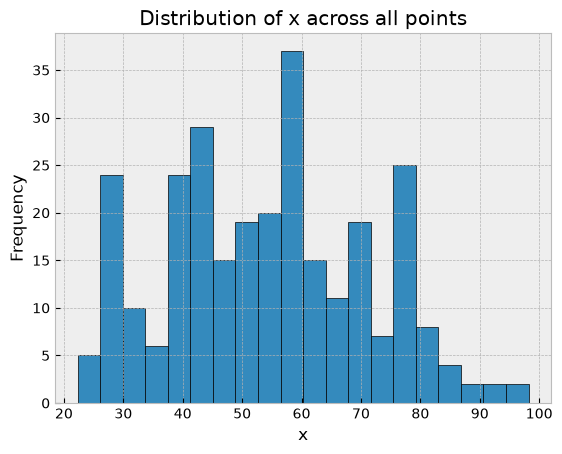

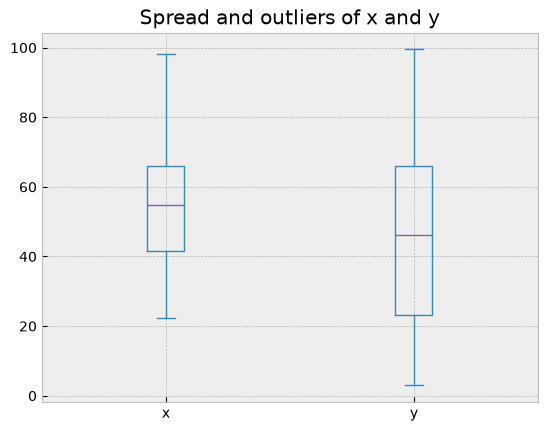

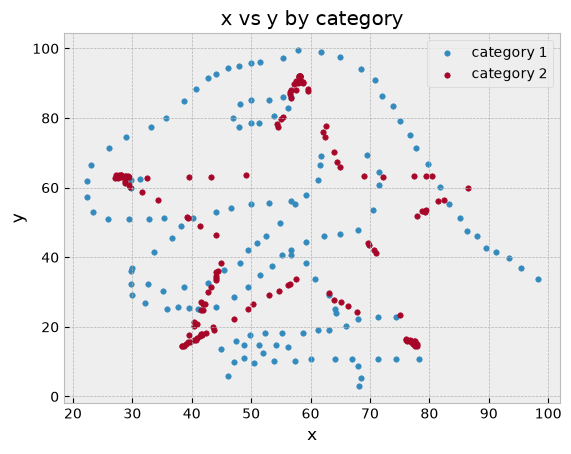

In [62]:
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('bmh')
mystery = pd.read_csv('data/mysterious_data.csv')

mystery.describe()
mystery.groupby('category')[['x', 'y']].agg(['mean', 'std', 'count'])

mystery['x'].plot.hist(bins=20, edgecolor='black')
plt.title('Distribution of x across all points')
plt.xlabel('x')
plt.show()

mystery[['x', 'y']].plot.box()
plt.title('Spread and outliers of x and y')
plt.show()

for cat, grp in mystery.groupby('category'):
    plt.scatter(grp['x'], grp['y'], s=15, label=f'category {cat}')
plt.xlabel('x')
plt.ylabel('y')
plt.title('x vs y by category')
plt.legend()
plt.show()